In [151]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Загрузка данных и начальный анализ данных

In [152]:
from google.colab import files

upl = files.upload()

Saving used_cars.csv to used_cars (2).csv


In [153]:
df = pd.read_csv('used_cars.csv')
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [154]:
df.shape

(4009, 12)

In [155]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB




*   Есть пропуски у fuel_type, accident, clean_title
*   У milage и price не int



Преобразуем millage и price в числа

In [156]:
df['milage'] = (df['milage']
                .str.replace(',', '', regex=False)
                .str.replace('mi.', '', regex=False)
                .astype(int))

df['price'] = (df['price']
                .str.replace('$', '', regex=False)
                .str.replace(',', '', regex=False)
                .astype(int))

In [157]:
df[['milage', 'price']].head()

,milage,price
0,51000,10300
1,34742,38005
2,22372,54598
3,88900,15500
4,9835,34999


In [158]:
df[['milage', 'price']].dtypes

,0
milage,int64
price,int64


## 2. EDA (Exploratory Data Analysis)

Проведем разделение данных на обучающую и тестовую выборку.

In [159]:
from sklearn.model_selection import train_test_split

In [160]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=142)

print('Обучающая выборка:', df_train.shape)
print('Тестовая выборка:', df_test.shape)

Обучающая выборка: (3207, 12)
Тестовая выборка: (802, 12)


Работаем с числовыми признаками

In [161]:
df_train.describe().round(2)

,model_year,milage,price
count,3207.00,3207.00,3207.00
mean,2015.50,64987.38,44994.82
std,6.09,51997.38,84351.55
min,1993.00,100.00,2300.00
25%,2012.00,23142.00,17000.00
50%,2017.00,53433.00,31331.00
75%,2020.00,94245.50,49897.50
max,2024.00,399000.00,2954083.00


* Есть автомобили с заметно большим пробегом относительно основной части выборки - кандидаты в выбросы. Соотношение среднего и медианы позволяет предположить правостороннюю асимметрию распределения
* Очень дорогие автомобили повышают среднее относительно медианы. Это позволяет предположить выраженный правый хвост распределения и наличие кандидатов в выбросы среди дорогих объявлений.


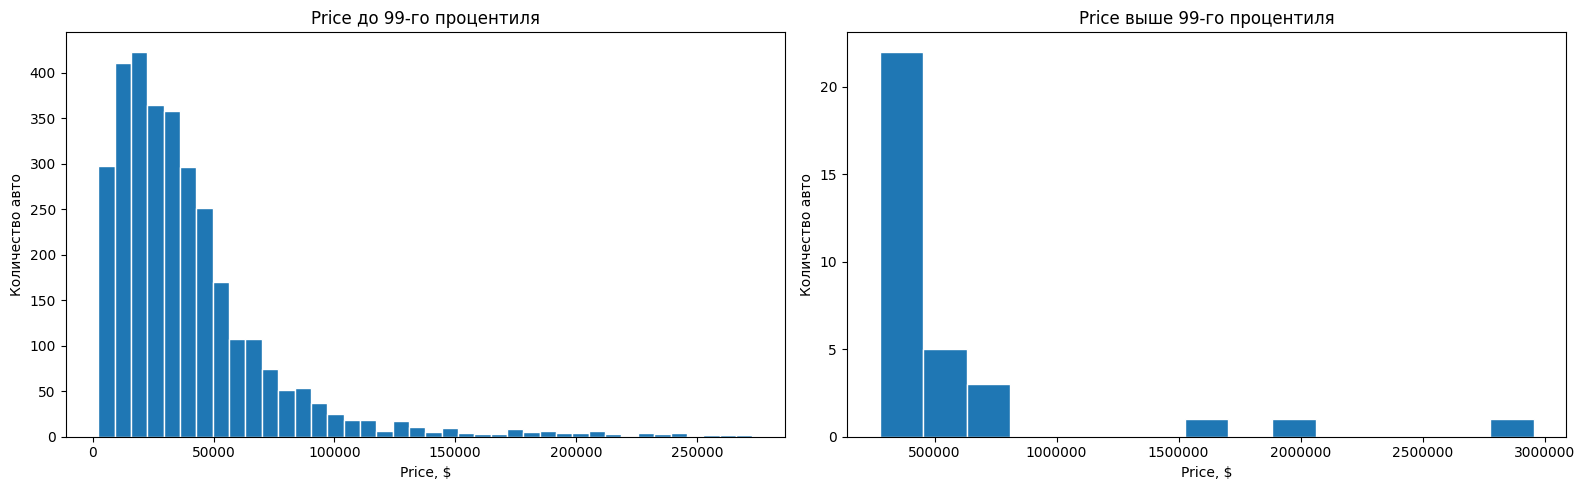

In [162]:
prices = df_train['price']
limit = prices.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(prices[prices <= limit], bins=40, edgecolor='white')
axes[0].set(title='Price до 99-го процентиля',
            xlabel='Price, $', ylabel='Количество авто')

axes[1].hist(prices[prices > limit], bins=15, edgecolor='white')
axes[1].set(title='Price выше 99-го процентиля',
            xlabel='Price, $', ylabel='Количество авто')
axes[1].ticklabel_format(axis='x', style='plain')

plt.tight_layout()
plt.show()


* По распределению видно, что она имеет выраженную правостороннюю асимметрию. Основная масса автомобилей стоит несколько десятков тысяч долларов. При увеличении цены кол-во сокращается, встречаются отдельные автомобили стоимостью более миллиона долларов.

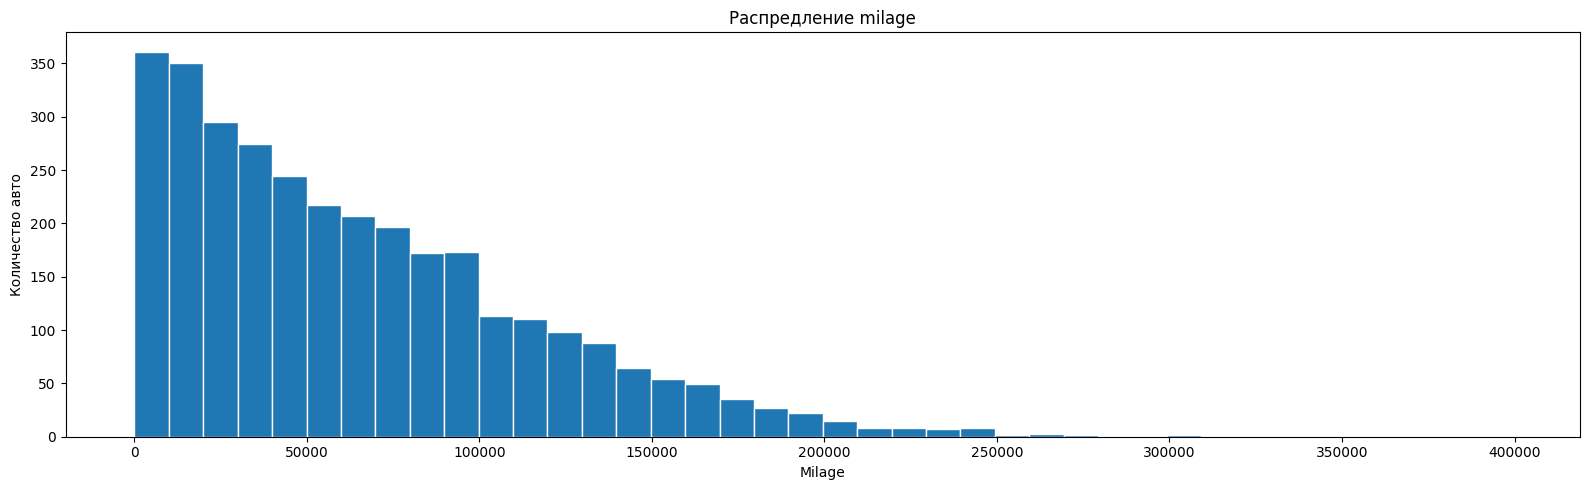

In [163]:
fig, ax = plt.subplots(figsize=(16, 5))

ax.hist(df_train['milage'], bins=40, edgecolor='white')
ax.set(title='Распредление milage',
       xlabel='Milage', ylabel='Количество авто')

plt.tight_layout()
plt.show()

* Распределение пробега имеет правостороннюю асимметрию. Автомобили с небольшим пробегом встречаются чаще. С увеличением пробега количество наблюдений в целом сокращается, формируется длинный правый хвост. Автомобили с пробегом более 200 тысяч встречаются редко.

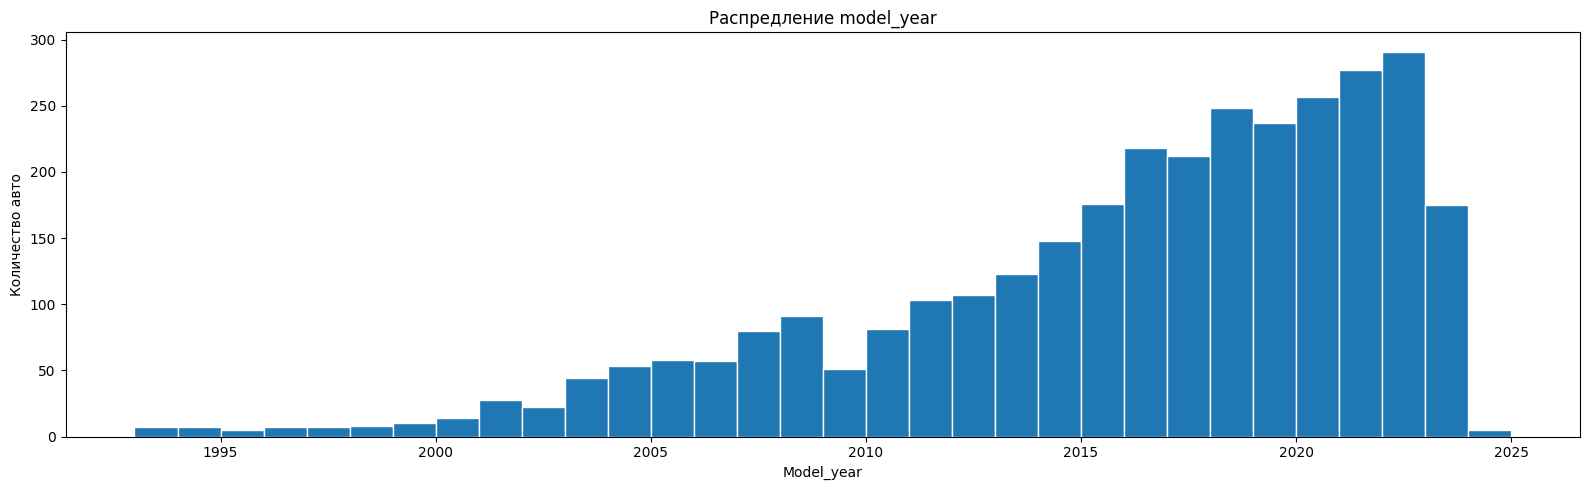

In [164]:
fig, ax = plt.subplots(figsize=(16, 5))
bins = range(df_train['model_year'].min(), df_train['model_year'].max() + 2)

ax.hist(df_train['model_year'], bins=bins, edgecolor='white')
ax.set(title='Распредление model_year',
       xlabel='Model_year', ylabel='Количество авто')

plt.tight_layout()
plt.show()

* В обучающей выборке преобладают автомобили 2016–2023 годов выпуска. Автомобили до 2000 года встречаются редко. Автомобилей 2024 года также немного.

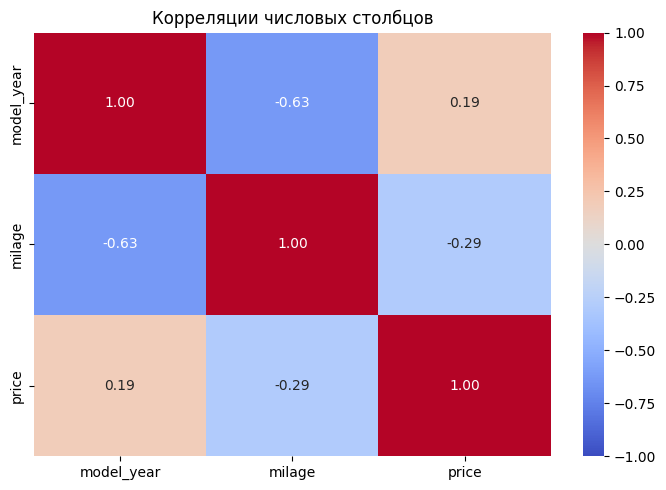

In [165]:
numiric_cols = ['model_year', 'milage', 'price']
corr = df_train[numiric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=ax)

ax.set_title('Корреляции числовых столбцов')

plt.tight_layout()
plt.show()

* Более новым автомобилям в целом соответствует меньший пробег. Это заметная отрицательная линейная связь.
* Более новым автомобилям в целом соответствует более высокая цена, но парная линейная связь слабая.
* С увеличением пробега цена в целом снижается, однако линейная связь также сравнительно слабая.

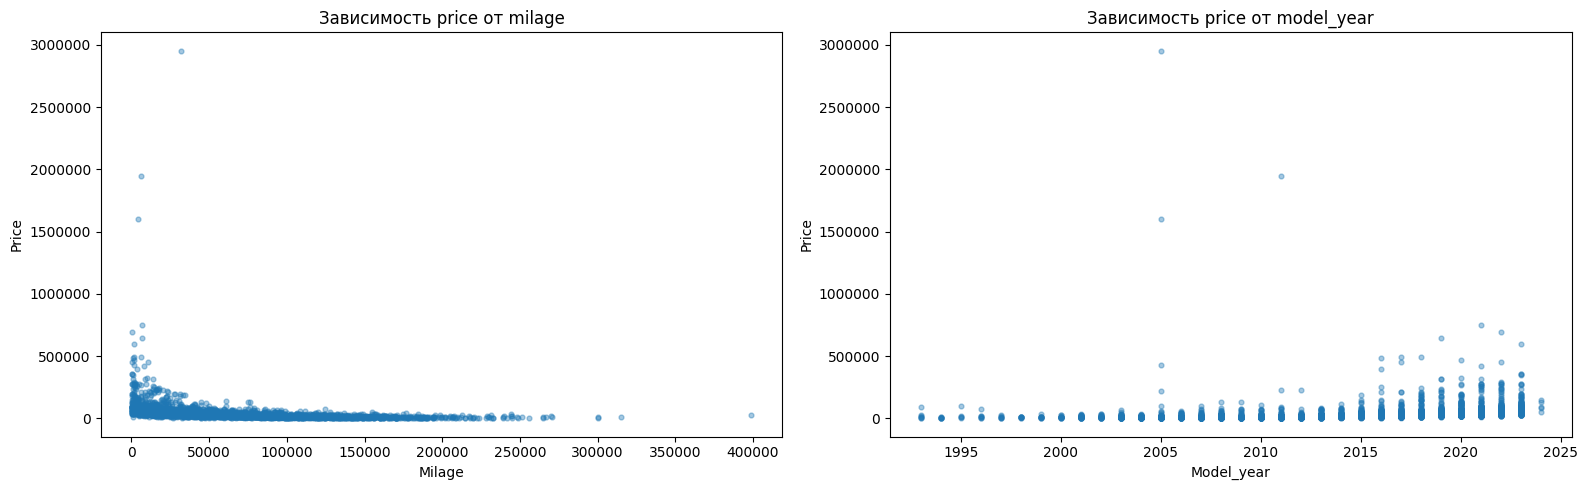

In [166]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].scatter(df_train['milage'], df_train['price'],
                s=12, alpha=0.4)
axes[0].set(title='Зависимость price от milage',
            xlabel='Milage', ylabel='Price')
axes[0].ticklabel_format(axis='y', style='plain')

axes[1].scatter(df_train['model_year'], df_train['price'],
                s=12, alpha=0.4)
axes[1].set(title='Зависимость price от model_year',
            xlabel='Model_year', ylabel='Price')
axes[1].ticklabel_format(axis='y', style='plain')

plt.tight_layout()
plt.show()

* Автомобили с наиболее высокой ценой имеют небольшой пробег, но относятся к разным годам выпуска, включая не самые новые. Предполагаем, что их высокая стоимость связана также с другими характеристиками — например, маркой и конкретной моделью автомобиля.

In [167]:
df_train.nlargest(5, 'price')[
    ['brand', 'model', 'model_year', 'milage', 'price']
]

,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000,2954083
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330,1950995
3046,Porsche,Carrera GT Base,2005,4400,1599000
1356,Lamborghini,Aventador SVJ Base,2021,6987,749950
624,Rolls-Royce,Cullinan,2022,398,695000


Работает с не числовыми признаками

In [168]:
for col in ['fuel_type', 'accident', 'clean_title']:
  print(col)
  display(df_train[col].value_counts(dropna=False))

fuel_type


,count
fuel_type,
Gasoline,2657
Hybrid,155
NaN,127
E85 Flex Fuel,110
Diesel,96
–,33
Plug-In Hybrid,28
not supported,1


accident


,count
accident,
None reported,2318
At least 1 accident or damage reported,803
NaN,86


clean_title


,count
clean_title,
Yes,2740
NaN,467


* fuel_type: not supported и - ?? надо проверить описание двигателя может помочь понять, что скрывается за такой категорией.

In [169]:
df_train.loc[
    df_train['fuel_type'] == 'not supported',
    ['brand', 'model', 'fuel_type', 'engine']
]

,brand,model,fuel_type,engine
2894,Toyota,Mirai Limited,not supported,182.0HP Electric Motor Hydrogen Fuel


* Оказалось это электричка почти - электромотор и водородные топливные элементы.

In [170]:
df_train.loc[
    df_train['fuel_type'].isin(['–', '—', '-']),
    ['brand', 'model', 'fuel_type', 'engine']
]

,brand,model,fuel_type,engine
2103,Volvo,850 Turbo,–,–
3952,Dodge,Ram 3500 Quad Cab DRW,–,–
3984,Toyota,Land Cruiser Base,–,–
1083,Dodge,Challenger R/T,–,–
2608,Jeep,Wrangler S,–,–
257,Toyota,Land Cruiser Base,–,–
2505,Dodge,Challenger SRT8,–,–
1681,Acura,Integra GS-R,–,–
2574,Cadillac,DeVille Base,–,–
995,Dodge,Challenger R/T Scat Pack,–,–


* В fuel_type обнаружены разные обозначения отсутствующей или нестандартной информации: 127 значений NaN, 33 прочерка и одно значение not supported
* В engine также присутствуют скрытые пропуски, обозначенные прочерком. В просмотренных строках они совпадают с прочерками в fuel_type. Такие значения не учитываются как пропуски при вызове .isna().
* Признаки fuel_type и engine могут частично дублировать информацию. Предполагаем, что более подробное описание двигателя позволит обойтись без отдельного типа топлива.

In [171]:
df_train.loc[
    df_train['fuel_type'].isna(),
    ['brand', 'model', 'fuel_type', 'engine']
].head(127)

,brand,model,fuel_type,engine
2066,Chevrolet,Bolt EV LT,NaN,200.0HP Electric Motor Electric Fuel System
1901,Tesla,Model S Performance,NaN,778.0HP Electric Motor Electric Fuel System
1330,Rivian,R1S Adventure Package,NaN,835.0HP Electric Motor Electric Fuel System
2472,Rivian,R1S Launch Edition,NaN,835.0HP Electric Motor Electric Fuel System
9,Tesla,Model X Long Range Plus,NaN,534.0HP Electric Motor Electric Fuel System
...,...,...,...,...
3961,Tesla,Model 3 Long Range,NaN,Electric
2795,Mercedes-Benz,EQS 450+ Base,NaN,329.0HP Electric Motor Electric Fuel System
129,Lucid,Air Pure,NaN,620.0HP Electric Motor Electric Fuel System
1943,Tesla,Model 3 Standard Range Plus,NaN,Electric Motor Electric Fuel System


In [172]:
df_train.loc[
    df_train['fuel_type'].isna(), 'engine'
].value_counts(dropna=False)


,count
engine,
425.0HP Electric Motor Electric Fuel System,15
835.0HP Electric Motor Electric Fuel System,13
Electric,12
Electric Motor Electric Fuel System,7
455.0HP Electric Motor Electric Fuel System,7
271.0HP Electric Motor Electric Fuel System,7
518.0HP Electric Motor Electric Fuel System,6
355.0HP Electric Motor Electric Fuel System,3
670.0HP Electric Motor Electric Fuel System,3


* В fuel_type все NaN и not supported это электрички можно их в 1 категорию объеденить

In [173]:
df_train.groupby('accident', dropna=False)['price'].agg(
    ['count', 'median', 'mean']).round(2)

,count,median,mean
accident,,,
At least 1 accident or damage reported,803,20500.0,29490.47
None reported,2318,35900.0,50223.46
NaN,86,35057.5,48832.05


* У автомобилей с заявленными авариями или повреждениями средняя и медианная цены существенно ниже, чем у автомобилей без заявленных аварий. Цены автомобилей с неизвестной историей близки к группе без заявленных аварий. Пропуски в accident решено объединить с категорией None reported. Такое упрощение выбрано с учётом небольшого количества пропусков и близких средних и медианных цен этих групп.

In [174]:
df_train.groupby('clean_title', dropna=False)['price'].agg(
    ['count', 'median', 'mean']).round(2)

,count,median,mean
clean_title,,,
Yes,2740,29000.0,42098.35
NaN,467,42900.0,61989.08


* Пропуски предлагается выделить в категорию Unknown, сохранив различие между группами. Полезность самого признака проверим при обучении моделей.

In [175]:
cols = ['brand', 'model', 'engine','transmission', 'ext_col', 'int_col']

df_train[cols].nunique().sort_values(ascending=False)

for col in cols:
    counts = df_train[col].value_counts()

    print(col)
    print('Категорий, встречающихся один раз:', (counts == 1).sum())
    print('Автомобилей в категориях реже 5 раз:',counts[counts < 5].sum())

brand
Категорий, встречающихся один раз: 6
Автомобилей в категориях реже 5 раз: 22
model
Категорий, встречающихся один раз: 1036
Автомобилей в категориях реже 5 раз: 2366
engine
Категорий, встречающихся один раз: 469
Автомобилей в категориях реже 5 раз: 1491
transmission
Категорий, встречающихся один раз: 18
Автомобилей в категориях реже 5 раз: 43
ext_col
Категорий, встречающихся один раз: 171
Автомобилей в категориях реже 5 раз: 312
int_col
Категорий, встречающихся один раз: 83
Автомобилей в категориях реже 5 раз: 154


* Наиболее высокая доля редких категорий наблюдается в model и engine. Группировка с порогом 5 затронет соответственно 73,8% и 46,5% автомобилей. Способ обработки этих столбцов следует выбирать отдельно от остальных категориальных признаков.

In [176]:
print(
    df_train['transmission']
    .value_counts(dropna=False))

transmission
A/T                                                                 852
8-Speed A/T                                                         330
Transmission w/Dual Shift Mode                                      322
6-Speed A/T                                                         282
6-Speed M/T                                                         201
Automatic                                                           187
7-Speed A/T                                                         162
8-Speed Automatic                                                   139
10-Speed A/T                                                         93
5-Speed A/T                                                          65
9-Speed A/T                                                          59
4-Speed A/T                                                          59
6-Speed Automatic                                                    50
1-Speed A/T                                        

* Признак transmission содержит разные формы записи сходных характеристик, а также неоднозначные значения. При подготовке данных из transmission будут выделены тип коробки и количество передач. Неоднозначные обозначения типа коробки объединим в Other. Количество передач восстановим только при его явном указании.

In [177]:
for col in ['ext_col', 'int_col']:
    print(col)
    display(
        df_train[col]
        .value_counts(dropna=False)
        .head(15))

ext_col


,count
ext_col,
Black,729
White,662
Gray,407
Silver,296
Blue,274
Red,202
Green,63
Gold,39
Brown,33


int_col


,count
int_col,
Black,1635
Beige,431
Gray,382
Brown,125
–,101
White,98
Red,91
Jet Black,45
Ebony,31


* Для ext_col и int_col сохраняем отдельными категориями цвета, встречающиеся более 50 раз в обучающих данных.

In [178]:
brand_stats = (
    df_train.groupby('brand')['price']
    .agg(['count', 'median', 'mean'])
    .sort_values('count', ascending=False)
)

brand_stats.head(100).round(2)

,count,median,mean
brand,,,
Ford,313,32455.0,36420.45
BMW,296,33444.0,40174.31
Mercedes-Benz,249,38998.0,51601.43
Chevrolet,229,32000.0,37700.21
Porsche,164,64700.0,90573.60
Toyota,162,27425.0,29037.79
Audi,159,34000.0,40254.26
Lexus,128,30000.0,34488.70
Jeep,118,30000.0,30643.38


* Марки представлены неравномерно: одни насчитывают сотни автомобилей, другие — единичные наблюдения. У ряда распространённых марок медианные цены близки, однако между отдельными марками наблюдаются значительные различия. У некоторых марок среднее заметно превышает медиану из-за отдельных дорогих автомобилей.

## 3. Подготовка данных

In [179]:
print('Полных дубликатов:', df.duplicated().sum())

Полных дубликатов: 0


Заполним пропуски

In [180]:
for data in [df_train, df_test]:
    data['fuel_type'] = (
        data['fuel_type']
        .fillna('Electric')
        .replace('not supported', 'Electric')
        .replace(['–', '—', '-'], 'Unknown')
    )

    data['accident'] = data['accident'].fillna('None reported')
    data['clean_title'] = data['clean_title'].fillna('Unknown')

df_train[['fuel_type', 'accident', 'clean_title']].isna().sum()


,0
fuel_type,0
accident,0
clean_title,0


In [181]:
for col in ['ext_col', 'int_col']:
    counts = df_train[col].value_counts(dropna=False)

    print(col)
    display(counts[counts > 50])

ext_col


,count
ext_col,
Black,729
White,662
Gray,407
Silver,296
Blue,274
Red,202
Green,63


int_col


,count
int_col,
Black,1635
Beige,431
Gray,382
Brown,125
–,101
White,98
Red,91


In [182]:
color_cols = ['ext_col', 'int_col']

for data in [df_train, df_test]:
    data[color_cols] = (
        df.loc[data.index, color_cols]
        .replace(['–', '—', '-'], 'Unknown')
        .fillna('Unknown')
    )

In [183]:
for data in [df_train, df_test]:
    text = (
        data['transmission']
        .str.lower()
        .str.replace('single-speed', '1-speed', regex=False)
    )

    speeds = text.str.extract(
        r'(\d+)[ -]*(?:speed|spd)',
        expand=False
    )

    data['transmission_speeds'] = (
        pd.to_numeric(speeds, errors='coerce')
        .astype('Int64')
    )

df_train[['transmission', 'transmission_speeds']].drop_duplicates().head(15)


,transmission,transmission_speeds
963,8-Speed A/T,8
1864,A/T,<NA>
3525,7-Speed A/T,7
1901,1-Speed A/T,1
1549,7-Speed Automatic,7
1292,5-Speed A/T,5
3893,Transmission w/Dual Shift Mode,<NA>
1523,8-Speed Automatic,8
2109,4-Speed A/T,4
3659,10-Speed A/T,10


In [184]:
for data in [df_train, df_test]:
    text = data['transmission'].str.lower()

    automatic = text.str.contains(
    r'a/t|\bat\b|auto|cvt|variable|dual shift|dual[- ]clutch|dct|at/mt|single-speed',
    na=False
    )

    manual = text.str.contains(
        r'm/t|manual|\bmt\b',
        na=False
    )

    data['transmission_type'] = np.select(
        [automatic, manual],
        ['Automatic', 'Manual'],
        default='Other'
    )

df_train[
    ['transmission_type', 'transmission_speeds']
].drop_duplicates()

,transmission_type,transmission_speeds
963,Automatic,8
1864,Automatic,<NA>
3525,Automatic,7
1901,Automatic,1
1292,Automatic,5
2109,Automatic,4
3659,Automatic,10
1608,Automatic,6
2566,Manual,6
247,Automatic,9


In [185]:
df_train['transmission_type'].value_counts(dropna=False)

,count
transmission_type,
Automatic,2887
Manual,306
Other,14


In [186]:
df_train.loc[
    df_train['transmission_type'] == 'Other',
    ['transmission', 'transmission_speeds']
]

,transmission,transmission_speeds
5,F,<NA>
516,2,<NA>
2620,SCHEDULED FOR OR IN PRODUCTION,<NA>
2287,Transmission Overdrive Switch,<NA>
536,–,<NA>
665,Transmission Overdrive Switch,<NA>
2381,2,<NA>
476,F,<NA>
1356,7-Speed,7
3566,Transmission Overdrive Switch,<NA>


In [187]:
for data in [df_train, df_test]:
    data.drop(columns=['transmission'], inplace=True)

In [188]:
for data in [df_train, df_test]:
    engine = data['engine'].str.lower()

    hp = engine.str.extract(
        r'(\d+(?:\.\d+)?)\s*hp\b',
        expand=False
    )

    liters = engine.str.extract(
        r'(\d+(?:\.\d+)?)\s*(?:l|liters?)\b',
        expand=False
    )

    data['engine_hp'] = pd.to_numeric(hp, errors='coerce')
    data['engine_liters'] = pd.to_numeric(liters, errors='coerce')

display(
    df_train[['engine', 'engine_hp', 'engine_liters']].head(15)
)

df_train[['engine_hp', 'engine_liters']].isna().sum()

,engine,engine_hp,engine_liters
963,420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,420.0,6.2
1864,316.0HP 6.0L 8 Cylinder Engine Gasoline Fuel,316.0,6.0
2066,200.0HP Electric Motor Electric Fuel System,200.0,NaN
3525,503.0HP 4.0L 8 Cylinder Engine Gasoline Fuel,503.0,4.0
1901,778.0HP Electric Motor Electric Fuel System,778.0,NaN
2362,355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel,355.0,5.3
1549,3.0L V6 24V GDI DOHC Twin Turbo,NaN,3.0
1292,170.0HP 2.5L Straight 6 Cylinder Engine Gasoli...,170.0,2.5
2103,–,NaN,NaN
3893,176.0HP 2.5L 4 Cylinder Engine Gasoline Fuel,176.0,2.5


,0
engine_hp,631
engine_liters,162


In [189]:
for data in [df_train, df_test]:
    data.drop(columns=['engine'], inplace=True)

In [190]:
df_train[['engine_hp', 'engine_liters']].isna().sum()

,0
engine_hp,631
engine_liters,162


In [191]:
df_test[['engine_hp', 'engine_liters']].isna().sum()

,0
engine_hp,177
engine_liters,55


NaN или NA заполним медианой по выборке, но сохраним знание о том где заменили.

In [192]:
for data in [df_train, df_test]:
    mask = (
        (data['fuel_type'] == 'Electric')
        & data['engine_liters'].isna()
    )

    data.loc[mask, 'engine_liters'] = 0

In [193]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

cols = ['model_year', 'milage', 'transmission_speeds',
                'engine_hp', 'engine_liters']

numeric_pipeline = Pipeline([('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    ))
])

Теперь отделим входные признаки X от таргета Y

In [194]:
numeric_cols = [
    'model_year', 'milage', 'transmission_speeds',
    'engine_hp', 'engine_liters'
]

categorical_cols = [
    'brand', 'model', 'fuel_type',
    'ext_col', 'int_col',
    'accident', 'clean_title', 'transmission_type'
]

X_train = df_train[numeric_cols + categorical_cols]
y_train = df_train['price']

X_test = df_test[numeric_cols + categorical_cols]
y_test = df_test['price']

Кодирование категорий

In [195]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [196]:
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

## 4. OLS

In [197]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

OLS = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['model_year', 'milage',
                                                   'transmission_speeds',
                                                   'engine_hp',
                                                   'engine_liters']),
                                                 ('categorical',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['brand', 'model',
                                                   'fuel_type', 'ext_col',
                                                   'int_col', 'accident',
                                                   'clean_title',
                                                   'transmission_type'])])),
                ('model', LinearRegression())])

In [198]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=142
)

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

scores_OLS = cross_validate(
    OLS,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

In [209]:
OLS_cv = pd.DataFrame({
    'Train MAE': -scores_OLS['train_MAE'],
    'Val MAE': -scores_OLS['test_MAE'],
    'Val RMSE': -scores_OLS['test_RMSE'],
    'Val R2': scores_OLS['test_R2']
}, index=range(1, 6))

display(OLS_cv.round(2))

print('\n')
display(OLS_cv.agg(['mean', 'std']).round(2))

,Train MAE,Val MAE,Val RMSE,Val R2
1,5959.91,19730.44,71502.87,0.31
2,5966.53,17757.12,34648.17,0.54
3,5309.01,20092.48,96770.67,-0.20
4,5308.94,17356.57,62314.52,-1.44
5,2692.38,18110.57,120236.00,0.10


,Train MAE,Val MAE,Val RMSE,Val R2
mean,5047.35,18609.44,77094.45,-0.14
std,1356.51,1224.86,32786.22,0.78


## 5. Ridge

In [210]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1))
])

scores_ridge = cross_validate(
    ridge_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

In [211]:
ridge_cv = pd.DataFrame({
    'Train MAE': -scores_ridge['train_MAE'],
    'Val MAE': -scores_ridge['test_MAE'],
    'Val RMSE': -scores_ridge['test_RMSE'],
    'Val R2': scores_ridge['test_R2']
}, index=range(1, 6))

comparison = pd.DataFrame({
    'OLS': OLS_cv.mean(),
    'Ridge (alpha=1)': ridge_cv.mean()
}).T

display(comparison.round(2))

,Train MAE,Val MAE,Val RMSE,Val R2
OLS,5047.35,18609.44,77094.45,-0.14
Ridge (alpha=1),10178.62,18096.41,70618.21,0.16
